# Домашнее задание 3. Логистическая регрессия и Streamlit

## Описание

В этом задании вы реализуете логистическую регрессию своими руками, разберётесь с метриками качества классификации на реальных несбалансированных данных и упакуете итоговую модель в интерактивное веб-приложение на Streamlit.

- Первая часть посвящена реализации логистической регрессии с помощью градиентного и стохастического градиентного спуска.
- Вторая часть посвящена метрикам классификации: матрице ошибок, precision, recall, $F_\beta$, ROC- и PR-кривым, выбору порога.
- Третья часть посвящена работе с несбалансированными классами.
- Четвертая часть посвящена созданию демонстрации на Streamlit.

**Максимальный балл за задание: 10** (по 2.5 балла за каждую из четырёх частей).

## Общие требования к ДЗ-3

- Для каждого задания приведите код решения.
- Там, где требуется интерпретация, добавьте короткий текстовый вывод.
- Следите за тем, чтобы ноутбук выполнялся последовательно сверху вниз.
- Везде, где есть случайность, фиксируйте `random_state=42`.
- Тестовая выборка используется **только** для финальной оценки качества. Всё, что «подбирается» (гиперпараметры, порог, ресемплинг, параметры масштабирования), подбирается по тренировочной выборке.

> В каждой части оцениваются как код, так и ответы на вопросы. Если отсутствует одно из двух, часть баллов за соответствующее задание может быть снижена.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from threadpoolctl import threadpool_limits

from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

sns.set_style('darkgrid')
RANDOM_STATE = 42
blas_limits = threadpool_limits(limits=1)
BASE_DIR = Path.cwd() if (Path.cwd() / 'Data/wine_quality.csv').exists() else Path.cwd() / 'hw_3'

## <font color="green">Часть 1. Логистическая регрессия своими руками (2.5 балла)</font>

На лекции мы получили функцию потерь логистической регрессии из метода максимума правдоподобия. Если $p_i = \sigma(\langle w, x_i \rangle)$ – предсказанная вероятность класса 1 для $i$-го объекта, то

$$Q(w) = -\frac{1}{\ell}\sum_{i=1}^{\ell}\Big(y_i \log p_i + (1 - y_i)\log(1 - p_i)\Big) \to \min_w, \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Явной формулы для минимума, как у МНК, здесь нет, поэтому веса ищем градиентным спуском – так же, как на семинаре 3 для линейной регрессии.

**Подсказка.** Сначала выведите градиент $\nabla Q(w)$ на бумаге и запишите его в матричном виде через $X$, $y$ и вектор вероятностей $p$. Вывод градиента приводить в ноутбуке не обязательно, но на защите его могут попросить.

### Задание 1.1. Класс `LogReg` (1.5 балла)

Реализуйте класс логистической регрессии, обучаемой с помощью:
- **полного градиентного спуска** – `gd_type='full'` (1 балл);
- **стохастического градиентного спуска** – `gd_type='stochastic'`: на каждой итерации градиент оценивается по случайному батчу из `batch_size` объектов, как в функции `calc_grad_on_batch` с семинара 3 (0.5 балла).

**Требования:**
- Градиентный спуск записан в векторном виде. Циклы средствами Python допускаются **только** по итерациям градиентного спуска.
- Свободный член $w_0$ учитывается так, как на лекции: внутри `fit` и `predict_proba` к матрице признаков добавляется фиктивный признак $x_0 = 1$ (первым столбцом). Таким образом, `self.w` имеет размер `d + 1`, и `self.w[0]` – это свободный член.
- Критерии остановки (одновременно):
  - L2 норма разности весов на двух соседних итерациях меньше `tolerance`;
  - достигнуто максимальное число итераций `max_iter`.
- Атрибут `loss_history` после вызова `fit` содержит значение функции потерь **на всей обучающей выборке** для каждой итерации, начиная с первой (до совершения первого шага по антиградиенту).
- Веса инициализируются вектором `w0`, если он передан, иначе – нулевым вектором.
- `predict_proba` возвращает массив размера `(N, 2)`: в первом столбце вероятность класса 0, во втором – класса 1 (как в `sklearn`).
- `predict` возвращает метки классов `0/1`, сравнивая вероятность класса 1 с порогом `threshold`.
- При вычислении логарифма в `calc_loss` позаботьтесь о вычислительной устойчивости: $\log 0$ давать не должно (например, используйте `np.clip`).

Полезно [почитать](https://scikit-learn.org/stable/developers/develop.html) о том, как устроены модели в `sklearn`.

**ВАЖНО!** Заполните шаблон ниже, не меняя структуру класса и сигнатуры методов. Добавлять свои вспомогательные методы можно.

In [2]:
class LogReg(BaseEstimator, ClassifierMixin):
    def __init__(self, gd_type='full', tolerance=1e-4, max_iter=1000,
                 w0=None, eta=1e-2, batch_size=32, random_state=42):
        self.gd_type = gd_type
        self.tolerance = tolerance
        self.max_iter = max_iter
        self.w0 = w0
        self.eta = eta
        self.batch_size = batch_size
        self.random_state = random_state

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) == 0:
            raise ValueError('Нужны непустые X (N, d) и y (N,)')
        if not np.isfinite(X).all() or not np.isin(y, [0, 1]).all():
            raise ValueError('X должен быть конечным, y — бинарным')
        if self.gd_type not in ('full', 'stochastic'):
            raise ValueError("gd_type должен быть 'full' или 'stochastic'")
        if self.eta <= 0 or self.tolerance < 0 or self.max_iter < 1:
            raise ValueError('eta > 0, tolerance >= 0, max_iter >= 1')
        if not isinstance(self.max_iter, (int, np.integer)):
            raise ValueError('max_iter должен быть целым')
        if not isinstance(self.batch_size, (int, np.integer)) or self.batch_size < 1:
            raise ValueError('batch_size должен быть положительным целым')
        self.classes_ = np.array([0, 1])
        self.n_features_in_ = X.shape[1]
        self.loss_history = []
        rng = np.random.default_rng(self.random_state)
        X_bias = np.column_stack((np.ones(len(X)), X))
        self.w = (np.zeros(X_bias.shape[1]) if self.w0 is None
                  else np.array(self.w0, dtype=float, copy=True))
        if self.w.shape != (X_bias.shape[1],) or not np.isfinite(self.w).all():
            raise ValueError('w0 должен содержать d + 1 конечных весов')
        self.stop_reason_ = 'max_iter'
        for iteration in range(self.max_iter):
            self.loss_history.append(self.calc_loss(X_bias, y))
            if self.gd_type == 'stochastic':
                indices = rng.choice(len(y), size=min(self.batch_size, len(y)), replace=False)
                gradient = self.calc_gradient(X_bias[indices], y[indices])
            else:
                gradient = self.calc_gradient(X_bias, y)
            w_next = self.w - self.eta * gradient
            self.last_step_norm_ = np.linalg.norm(w_next - self.w)
            self.w = w_next
            self.n_iter_ = iteration + 1
            if self.last_step_norm_ < self.tolerance:
                self.stop_reason_ = 'tolerance'
                break
        self.final_loss_ = self.calc_loss(X_bias, y)
        self.intercept_ = self.w[:1].copy()
        self.coef_ = self.w[None, 1:].copy()
        return self

    def sigmoid(self, z):
        return np.exp(-np.logaddexp(0, -np.asarray(z, dtype=float)))

    def predict_proba(self, X):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        X = np.asarray(X, dtype=float)
        if X.ndim != 2 or X.shape[1] != len(self.w) - 1 or not np.isfinite(X).all():
            raise ValueError('Неверная форма X или нечисловые/бесконечные значения')
        X_bias = np.column_stack((np.ones(len(X)), X))
        p = self.sigmoid(X_bias @ self.w)
        return np.column_stack((1 - p, p))

    def predict(self, X, threshold=0.5):
        if getattr(self, 'w', None) is None:
            raise Exception('Not trained yet')
        if not 0 <= threshold <= 1:
            raise ValueError('threshold должен лежать в [0, 1]')
        return (self.predict_proba(X)[:, 1] >= threshold).astype(int)

    def calc_gradient(self, X, y):
        return X.T @ (self.sigmoid(X @ self.w) - y) / len(y)

    def calc_loss(self, X, y):
        z = X @ self.w
        return float(np.mean(np.logaddexp(0, z) - y * z))

Ячейка ниже проверяет вашу реализацию градиента численно: сравнивает `calc_gradient` с конечными разностями функции `calc_loss`. Она не оценивается, но если проверка не проходит – ищите ошибку, прежде чем идти дальше.

In [3]:
def check_gradient(model, d=5, N=50, eps=1e-6, seed=42):
    rng = np.random.default_rng(seed)
    X = np.hstack([np.ones((N, 1)), rng.normal(size=(N, d))])
    y = rng.integers(0, 2, size=N).astype(float)
    model.w = rng.normal(size=d + 1)

    analytic = model.calc_gradient(X, y)
    numeric = np.zeros(d + 1)
    w = model.w.copy()
    for j in range(d + 1):
        e = np.zeros(d + 1)
        e[j] = eps
        model.w = w + e
        loss_plus = model.calc_loss(X, y)
        model.w = w - e
        loss_minus = model.calc_loss(X, y)
        numeric[j] = (loss_plus - loss_minus) / (2 * eps)
    model.w = w
    return np.max(np.abs(analytic - numeric))


err = check_gradient(LogReg())
print(f'max |analytic - numeric| = {err:.2e}')
assert err < 1e-5, 'Градиент не совпадает с численным — проверьте calc_gradient и calc_loss'

max |analytic - numeric| = 2.49e-10


Теперь проверим работу класса на синтетических данных.

In [4]:
X, y = make_classification(
    n_samples=20000, n_features=20, n_informative=5,
    random_state=RANDOM_STATE)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE)

sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

### Задание 1.2. Обучение и сходимость (0.25 балла)

1. Обучите две модели: `LogReg(gd_type='full')` и `LogReg(gd_type='stochastic')` с параметрами по умолчанию.
2. Для каждой модели выведите число сделанных итераций и постройте на одном графике `loss_history` обеих моделей.
3. Ответьте на вопросы:
   - По какому критерию остановилась каждая модель – по `tolerance` или по `max_iter`?
   - Почему стохастическому спуску с постоянным шагом трудно остановиться по критерию `tolerance`?
   - Чем отличаются графики функции потерь?
   - Сколько объектов «просматривает» за одну итерацию каждый из методов?

In [5]:
gd = LogReg(gd_type='full').fit(X_train, y_train)
sgd = LogReg(gd_type='stochastic').fit(X_train, y_train)
convergence = pd.DataFrame([
    {'method': name, 'iterations': model.n_iter_, 'stop': model.stop_reason_,
     'step_norm': model.last_step_norm_, 'final_loss': model.final_loss_}
    for name, model in [('GD', gd), ('SGD', sgd)]
]).set_index('method')

In [6]:
convergence

,iterations,stop,step_norm,final_loss
method,,,,
GD,1000,max_iter,0.000399,0.512435
SGD,1000,max_iter,0.003895,0.512909


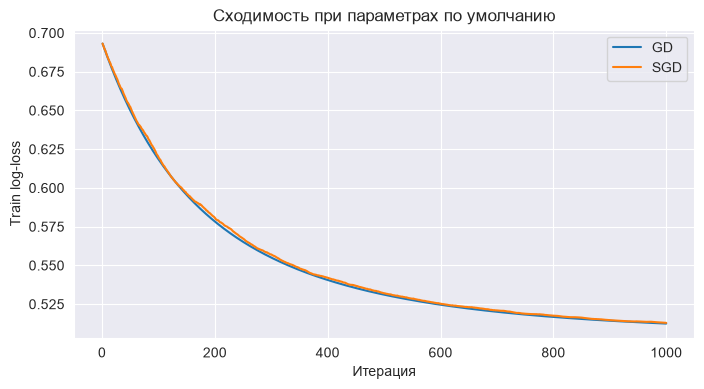

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for name, model in [('GD', gd), ('SGD', sgd)]:
    ax.plot(np.arange(1, len(model.loss_history) + 1), model.loss_history, label=name)
ax.set(xlabel='Итерация', ylabel='Train log-loss', title='Сходимость при параметрах по умолчанию')
ax.legend()
plt.show()

Обе модели остановились после 1000 итераций по max_iter. Норма изменения весов осталась больше tolerance.

У стохастического спуска градиент меняется из-за случайного выбора батча. При постоянном шаге веса продолжают колебаться около минимума.

У полного спуска функция потерь снижается плавно. У стохастического спуска на графике есть колебания.

Для расчета градиента полный спуск использует 14000 объектов за итерацию, стохастический использует 32. Для записи функции потерь оба метода дополнительно используют всю обучающую выборку.

### Задание 1.3. Длина шага (0.25 балла)

Для полного градиентного спуска обучите модели с сеткой `eta` из списка `[1e-3, 1e-2, 1e-1, 1, 10]` и постройте графики `loss_history` (удобно в логарифмической шкале по оси `x`). Выведите для каждого `eta` финальное значение функции потерь и число итераций.

Как длина шага влияет на скорость и качество сходимости? Есть ли значения `eta`, при которых спуск ведёт себя плохо?

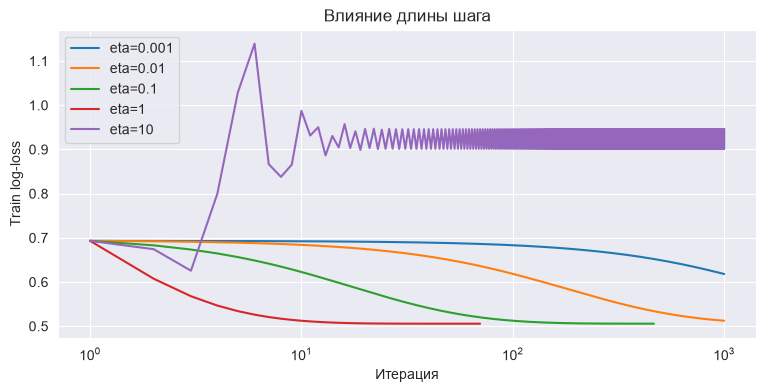

In [8]:
eta_models = {}
fig, ax = plt.subplots(figsize=(9, 4))
for eta in [1e-3, 1e-2, 1e-1, 1, 10]:
    model = LogReg(eta=eta).fit(X_train, y_train)
    eta_models[eta] = model
    ax.plot(np.arange(1, model.n_iter_ + 1), model.loss_history, label=f'eta={eta:g}')
ax.set(xscale='log', xlabel='Итерация', ylabel='Train log-loss', title='Влияние длины шага')
ax.legend()
plt.show()
eta_table = pd.DataFrame([
    {'eta': eta, 'iterations': model.n_iter_, 'stop': model.stop_reason_,
     'final_loss': model.final_loss_} for eta, model in eta_models.items()
]).set_index('eta')

In [9]:
eta_table

,iterations,stop,final_loss
eta,,,
0.001,1000,max_iter,0.618087
0.010,1000,max_iter,0.512435
0.100,465,tolerance,0.505762
1.000,70,tolerance,0.505757
10.000,1000,max_iter,0.901345


При шаге 0.001 спуск идет медленно. За 1000 итераций функция потерь снизилась до 0.6181. При шаге 0.01 она снизилась до 0.5124.

При шагах 0.1 и 1 спуск остановился по tolerance за 465 и 70 итераций. Функция потерь составила около 0.50576.

При шаге 10 функция потерь колеблется и после 1000 итераций равна 0.9013. Слишком большой шаг мешает сходимости.

### Задание 1.4. Сравнение с `sklearn` (0.5 балла)

1. Обучите `LogisticRegression` из `sklearn` с параметрами по умолчанию.
2. Для трёх моделей (ваш GD, ваш SGD, `sklearn`) посчитайте на тестовой выборке accuracy и ROC-AUC и сведите их в таблицу `pd.DataFrame`.
3. Сравните веса вашей модели (GD) с весами модели `sklearn` (`intercept_` и `coef_`).

Ответьте на вопросы:
   - Совпадают ли метрики? Совпадают ли веса?
   - Что в модели `sklearn` по умолчанию делает её не равной вашей? Найдите ответ в [документации](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html). Как настроить `LogisticRegression`, чтобы она решала ту же задачу оптимизации, что и ваша модель?

In [10]:
sk_model = LogisticRegression().fit(X_train, y_train)
synthetic_metrics = pd.DataFrame([
    {'model': name, 'accuracy': metrics.accuracy_score(y_test, model.predict(X_test)),
     'ROC-AUC': metrics.roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])}
    for name, model in [('GD', gd), ('SGD', sgd), ('sklearn', sk_model)]
]).set_index('model')

In [11]:
synthetic_metrics

,accuracy,ROC-AUC
model,,
GD,0.7820,0.838787
SGD,0.7825,0.838115
sklearn,0.7765,0.838676


In [12]:
weights = pd.DataFrame({'GD': gd.w,
                       'sklearn': np.r_[sk_model.intercept_, sk_model.coef_.ravel()]},
                      index=['intercept'] + [f'x{i}' for i in range(X_train.shape[1])])
weights['difference'] = weights.GD - weights.sklearn

In [13]:
weights

,GD,sklearn,difference
intercept,-0.002114,-0.021880,0.019765
x0,0.006076,0.002741,0.003335
x1,0.006963,0.009039,-0.002077
x2,-0.547170,-0.722690,0.175520
x3,-0.144536,-0.262335,0.117799
x4,0.012487,0.016588,-0.004102
x5,-0.006325,-0.011488,0.005163
x6,0.000814,0.005587,-0.004773
x7,0.039084,0.057188,-0.018104
x8,-0.002425,-0.001239,-0.001185


In [14]:
gd_converged = LogReg(eta=1, max_iter=20000, tolerance=1e-8).fit(X_train, y_train)
sk_unregularized = LogisticRegression(C=np.inf, max_iter=10000, tol=1e-10).fit(X_train, y_train)
w_sk = np.r_[sk_unregularized.intercept_, sk_unregularized.coef_.ravel()]
print('GD без регуляризации, остановка:', gd_converged.stop_reason_, gd_converged.n_iter_)
print('max |w_GD - w_sklearn без регуляризации|:', np.max(np.abs(gd_converged.w - w_sk)))
print('max разница train-вероятностей:', np.max(np.abs(
    gd_converged.predict_proba(X_train) - sk_unregularized.predict_proba(X_train))))

GD без регуляризации, остановка: tolerance 167
max |w_GD - w_sklearn без регуляризации|: 5.414154213845279e-08
max разница train-вероятностей: 3.9326362971658924e-08


Метрики близки, но не совпадают. Accuracy полного спуска равна 0.7820, стохастического спуска 0.7825, модели sklearn 0.7765. ROC AUC составляет 0.83879, 0.83811 и 0.83868 соответственно.

Веса тоже различаются. Максимальная разница между весами полного спуска и sklearn составляет 0.1813.

В sklearn по умолчанию используется регуляризация L2 с параметром C, равным 1. В моей модели регуляризации нет. Также полный спуск с параметрами по умолчанию не успел сойтись.

Чтобы модели решали одну задачу, нужно отключить регуляризацию и добиться сходимости. В используемой версии sklearn для этого можно задать параметр C равным np.inf. После сходимости максимальная разница весов составила 0.000000054.

## <font color="green">Часть 2. Метрики классификации (2.5 балла)</font>

### Данные

Используем датасет [Wine Quality](https://archive.ics.uci.edu/dataset/186/wine+quality) (P. Cortez et al., 2009, лицензия CC BY 4.0).
Каждая строка – образец португальского вина: 11 физико-химических характеристик и признак `is_red` (1 - красное, 0 - белое). Эксперты оценили каждое вино по шкале от 0 до 10. Мы превратили оценку в бинарную целевую переменную:

- `target = 1` – «хорошее» вино (оценка не ниже 7);
- `target = 0` – все остальные.

**Сценарий.** Сервис по подписке каждый месяц рекомендует клиентам вина. Модель должна по результатам лабораторного анализа отбирать «хорошие» вина в подборку. Рекомендовать клиенту посредственное вино — плохо (клиент разочаруется), но и пропускать хорошие вина тоже не хочется (подборка получится скудной).

In [15]:
df_raw = pd.read_csv(BASE_DIR / 'Data/wine_quality.csv')
missing_count = int(df_raw.isna().sum().sum())
duplicate_count = int(df_raw.duplicated().sum())
print('Исходная форма:', df_raw.shape)
print('Пропуски:', missing_count, '; полные дубликаты:', duplicate_count)
df = df_raw.drop_duplicates().reset_index(drop=True)
print('После удаления повторов:', df.shape)
df.head()

Исходная форма: (6497, 13)
Пропуски: 0 ; полные дубликаты: 1177
После удаления повторов: (5320, 13)


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,is_red,target
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,1,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,1,0
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,1,0
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,1,0
4,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,1,0


In [16]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

print('Train:', X_train.shape, ' Test:', X_test.shape)

Train: (3724, 12)  Test: (1596, 12)


### Задание 2.1. Первичный анализ и accuracy (0.25 балла)

1. Проверьте данные на пропуски и полные дубликаты строк. Нужно ли удалять дубликаты в этой задаче? Посчитайте долю класса 1 (prevalence) в тренировочной и тестовой выборках. Зачем при разбиении был указан параметр `stratify=y`?
2. Посчитайте accuracy на тестовой выборке для константной модели, которая всегда отвечает «не хорошее вино» (класс 0).
3. Обучите пайплайн `make_pipeline(StandardScaler(), LogisticRegression())` и посчитайте его accuracy на тестовой выборке.

Сравните два числа. Почему accuracy плохо подходит для этой задачи?

In [17]:
print('Пропуски по столбцам:')

Пропуски по столбцам:


In [18]:
df_raw.isna().sum().to_frame('missing')

,missing
fixed_acidity,0
volatile_acidity,0
citric_acid,0
residual_sugar,0
chlorides,0
free_sulfur_dioxide,0
total_sulfur_dioxide,0
density,0
pH,0
sulphates,0


In [19]:
print('Полные дубликаты в исходных данных:', duplicate_count)
prevalence = pd.Series({'train': y_train.mean(), 'test': y_test.mean()}, name='prevalence')

Полные дубликаты в исходных данных: 1177


In [20]:
prevalence.to_frame()

,prevalence
train,0.189581
test,0.189850


In [21]:
assert not set(map(tuple, X_train.to_numpy())) & set(map(tuple, X_test.to_numpy()))
constant_accuracy = metrics.accuracy_score(y_test, np.zeros(len(y_test), dtype=int))
baseline = make_pipeline(StandardScaler(), LogisticRegression(random_state=RANDOM_STATE))
baseline.fit(X_train, y_train)
baseline_proba = baseline.predict_proba(X_test)[:, 1]
baseline_pred = (baseline_proba >= 0.5).astype(int)

In [22]:
pd.DataFrame({'accuracy': [constant_accuracy, metrics.accuracy_score(y_test, baseline_pred)]},
                     index=['Всегда 0', 'LogisticRegression'])

,accuracy
Всегда 0,0.810150
LogisticRegression,0.815163


Пропусков нет. В исходных данных 1177 полных дубликатов. Я удалил их до разбиения, чтобы одинаковые записи не попали в обучение и тест. После удаления осталось 5320 строк.

Доля класса 1 в обучающей выборке составляет 18.96 процента, в тестовой 18.98 процента. Параметр stratify сохраняет близкие доли классов в обеих выборках.

Accuracy константной модели равна 0.8102, логистической регрессии 0.8152. Accuracy плохо подходит для задачи, потому что высокая доля класса 0 позволяет получить большое значение даже без обнаружения хороших вин.

### Задание 2.2. Матрица ошибок своими руками (0.5 балла)

Для пайплайна логистической регрессии из задания 2.1 получите предсказания классов на тестовой выборке.

1. Посчитайте TP, TN, FP, FN **без функций из `sklearn.metrics`** – только средствами `numpy`/`pandas`.
2. Сравните результат с `metrics.confusion_matrix` и нарисуйте матрицу ошибок с помощью `metrics.ConfusionMatrixDisplay`.
3. Объясните в терминах сценария, что означают FP и FN в этой задаче. Какая из ошибок модели встречается чаще?

TP=92, TN=1209, FP=84, FN=211


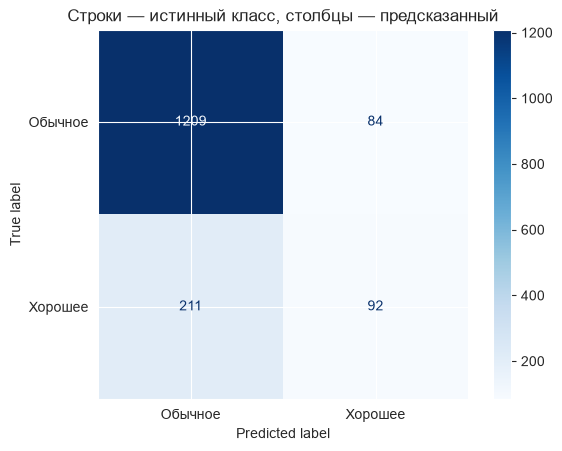

In [23]:
y_true = y_test.to_numpy()
TP = int(np.sum((y_true == 1) & (baseline_pred == 1)))
TN = int(np.sum((y_true == 0) & (baseline_pred == 0)))
FP = int(np.sum((y_true == 0) & (baseline_pred == 1)))
FN = int(np.sum((y_true == 1) & (baseline_pred == 0)))
manual_cm = np.array([[TN, FP], [FN, TP]])
assert np.array_equal(manual_cm, metrics.confusion_matrix(y_test, baseline_pred))
print(f'TP={TP}, TN={TN}, FP={FP}, FN={FN}')
metrics.ConfusionMatrixDisplay(manual_cm, display_labels=['Обычное', 'Хорошее']).plot(cmap='Blues')
plt.title('Строки — истинный класс, столбцы — предсказанный')
plt.show()

FP означает, что модель рекомендовала посредственное вино. Таких ошибок 84.

FN означает, что модель пропустила хорошее вино. Таких ошибок 211. Эта ошибка встречается чаще.

### Задание 2.3. Precision, recall, $F_\beta$ (0.5 балла)

1. Используя TP, TN, FP, FN из задания 2.2, посчитайте по формулам precision, recall, $F_1$, $F_{0.5}$ и $F_2$:

$$F_{\beta} = (1 + \beta^2)\frac{\text{Precision} \cdot \text{Recall}}{\beta^2 \cdot \text{Precision} + \text{Recall}}.$$

2. Проверьте свои значения с помощью `metrics.precision_score`, `metrics.recall_score`, `metrics.fbeta_score`.
3. Ответьте на вопросы:
   - Что больше ценится в $F_{0.5}$, а что в $F_2$ – precision или recall?
   - Какую из трёх F-мер вы бы выбрали для нашего сценария, если подписчики очень болезненно реагируют на посредственные вина в подборке? А если сервис позиционирует себя как «самая широкая подборка хороших вин»?

In [24]:
precision_manual = TP / (TP + FP) if TP + FP else 0.0
recall_manual = TP / (TP + FN) if TP + FN else 0.0

def fbeta_manual(precision, recall, beta):
    denominator = beta ** 2 * precision + recall
    return (1 + beta ** 2) * precision * recall / denominator if denominator else 0.0

manual_metrics = pd.Series({'precision': precision_manual, 'recall': recall_manual,
    'F1': fbeta_manual(precision_manual, recall_manual, 1),
    'F0.5': fbeta_manual(precision_manual, recall_manual, 0.5),
    'F2': fbeta_manual(precision_manual, recall_manual, 2)})
sklearn_metrics = pd.Series({'precision': metrics.precision_score(y_test, baseline_pred, zero_division=0),
    'recall': metrics.recall_score(y_test, baseline_pred, zero_division=0),
    **{name: metrics.fbeta_score(y_test, baseline_pred, beta=beta, zero_division=0)
       for name, beta in [('F1', 1), ('F0.5', 0.5), ('F2', 2)]}})
assert np.allclose(manual_metrics, sklearn_metrics)

In [25]:
pd.DataFrame({'по формулам': manual_metrics, 'sklearn': sklearn_metrics})

,по формулам,sklearn
precision,0.522727,0.522727
recall,0.303630,0.303630
F1,0.384134,0.384134
F0.5,0.456802,0.456802
F2,0.331412,0.331412


F0.5 больше учитывает precision, F2 больше учитывает recall. F1 учитывает их одинаково.

Если подписчики болезненно реагируют на посредственные вина, я выбрал бы F0.5. Если важнее найти как можно больше хороших вин, я выбрал бы F2.

### Задание 2.4. ROC- и PR-кривые (0.5 балла)

Сравним две модели:
- `make_pipeline(StandardScaler(), LogisticRegression())` из `sklearn`;
- ваш `LogReg(gd_type='full')` из части 1 (не забудьте масштабировать признаки, подберите `eta` и `max_iter` так, чтобы спуск сошёлся).

1. Для каждой модели получите на тестовой выборке **непрерывные оценки** (score) – вероятность класса 1.
2. Постройте ROC-кривые двух моделей на одном графике и PR-кривые двух моделей на другом графике. На PR-графике отметьте горизонтальной линией уровень случайной модели.
3. Посчитайте ROC-AUC (`metrics.roc_auc_score`) и PR-AUC (`metrics.average_precision_score`) и сведите в таблицу.
4. Возьмите вероятности $p$ класса 1 модели из `sklearn` и посчитайте ROC-AUC для преобразованных оценок: $10 \cdot p$, $p^3$, $\log\frac{p}{1-p}$, $-p$. Объясните результат.

Ответьте на вопросы:
- Какая модель лучше? Совпадает ли ранжирование моделей по ROC-AUC и по PR-AUC?
- Чему равен PR-AUC случайной модели в этой задаче и почему он не равен 0.5?
- Что получится, если подать в `roc_auc_score` предсказанные метки классов?

Свой GD: tolerance 9113 9.99880051420119e-08


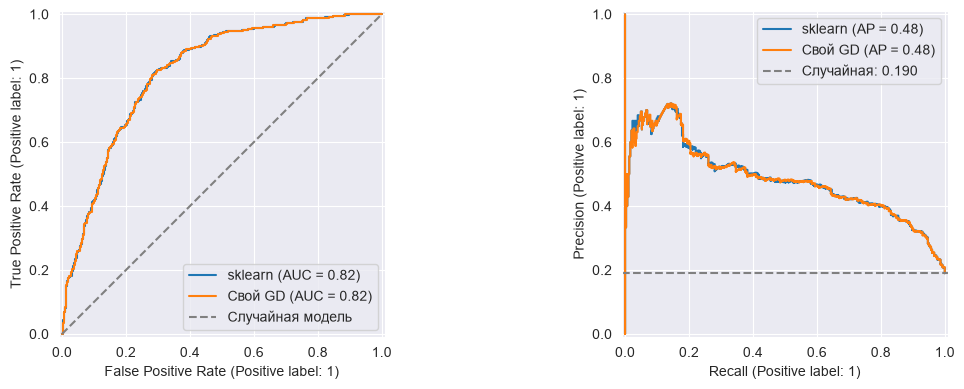

In [26]:
wine_gd = make_pipeline(StandardScaler(), LogReg(eta=0.5, max_iter=100000, tolerance=1e-7))
wine_gd.fit(X_train, y_train)
print('Свой GD:', wine_gd[-1].stop_reason_, wine_gd[-1].n_iter_, wine_gd[-1].last_step_norm_)
assert wine_gd[-1].stop_reason_ == 'tolerance'
wine_gd_proba = wine_gd.predict_proba(X_test)[:, 1]
curve_scores = {'sklearn': baseline_proba, 'Свой GD': wine_gd_proba}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, scores in curve_scores.items():
    metrics.RocCurveDisplay.from_predictions(y_test, scores, name=name, ax=axes[0])
    metrics.PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], '--', color='grey', label='Случайная модель')
axes[0].legend()
axes[1].axhline(y_test.mean(), linestyle='--', color='grey', label=f'Случайная: {y_test.mean():.3f}')
axes[1].legend()
plt.tight_layout()
plt.show()
auc_table = pd.DataFrame([
    {'model': name, 'ROC-AUC': metrics.roc_auc_score(y_test, scores),
     'PR-AUC (AP)': metrics.average_precision_score(y_test, scores)}
    for name, scores in curve_scores.items()
]).set_index('model')

In [27]:
auc_table

,ROC-AUC,PR-AUC (AP)
model,,
sklearn,0.820876,0.484766
Свой GD,0.820562,0.483769


In [28]:
p = baseline_proba
p_safe = np.clip(p, np.finfo(float).eps, 1 - np.finfo(float).eps)
auc_transforms = pd.Series({name: metrics.roc_auc_score(y_test, scores)
    for name, scores in {'p': p, '10*p': 10*p, 'p**3': p**3,
                        'logit(p)': np.log(p_safe / (1-p_safe)), '-p': -p,
                        'Метки (p >= 0.5)': baseline_pred}.items()}, name='ROC-AUC')

In [29]:
auc_transforms.to_frame()

,ROC-AUC
p,0.820876
10*p,0.820876
p**3,0.820876
logit(p),0.820876
-p,0.179124
Метки (p >= 0.5),0.619333


Модель sklearn немного лучше по обеим метрикам. Ее ROC AUC равна 0.82088, у моей модели 0.82056. PR AUC составляет 0.48477 и 0.48377 соответственно. Порядок моделей по обеим метрикам совпадает.

Уровень случайной модели для PR AUC составляет около 0.18985. Он соответствует доле хороших вин в тестовой выборке. Значение не равно 0.5, потому что классы несбалансированы.

Умножение вероятности на 10, возведение в куб и логарифм отношения вероятностей сохраняют порядок объектов. Поэтому ROC AUC остается равной 0.82088. Смена знака вероятности меняет порядок на обратный, и ROC AUC становится равной 0.17912.

Если передать предсказанные метки классов, ROC AUC будет равна 0.61933. При этом теряется информация о порядке объектов внутри каждого предсказанного класса.

### Задание 2.5. Выбор порога (0.75 балла)

Порог 0.5 у логистической регрессии ничем не выделен – его можно и нужно выбирать под задачу. Но подбирать порог на тестовой выборке нельзя: тогда оценка качества на тесте окажется завышенной.

1. Выделите из тренировочной выборки валидационную (`test_size=0.25`, `stratify`, `random_state=42`). Обучите пайплайн логистической регрессии на оставшейся части и получите вероятности на валидации.
2. Постройте на одном графике зависимость precision, recall и $F_1$ на валидации от порога $t \in [0, 1]$.
3. По валидации выберите два порога:
   - $t_{F_1}$ – максимизирующий $F_1$;
   - $t_{R}$ – дающий максимальный precision при условии recall $\ge 0.7$ (сервис хочет, чтобы в подборку попадало не меньше 70% хороших вин).
4. Переобучите пайплайн на всей тренировочной выборке и посчитайте на тестовой выборке precision, recall и $F_1$ при порогах $0.5$, $t_{F_1}$ и $t_{R}$. Сведите результаты в таблицу.

Выполнилось ли на тесте условие recall $\ge 0.7$? Почему порог, подобранный на валидации, не гарантирует выполнения условия на новых данных? Какой порог вы бы выбрали для сценария из описания данных и почему?

In [30]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train, random_state=RANDOM_STATE)
validation_model = clone(baseline).fit(X_fit, y_fit)
val_proba = validation_model.predict_proba(X_val)[:, 1]
thresholds = np.unique(np.r_[0.0, val_proba, 1.0])
val_predictions = val_proba[:, None] >= thresholds[None, :]
val_positive = y_val.to_numpy()[:, None] == 1
val_tp = (val_predictions & val_positive).sum(axis=0)
val_fp = (val_predictions & ~val_positive).sum(axis=0)
val_precision = np.divide(val_tp, val_tp + val_fp, out=np.zeros(len(thresholds)), where=val_tp+val_fp > 0)
val_recall = val_tp / val_positive.sum()
val_f1 = np.divide(2*val_precision*val_recall, val_precision+val_recall,
                   out=np.zeros(len(thresholds)), where=val_precision+val_recall > 0)
f1_index = np.flatnonzero(val_f1 == val_f1.max())[-1]
eligible = np.flatnonzero(val_recall >= 0.7)
r_index = eligible[np.flatnonzero(val_precision[eligible] == val_precision[eligible].max())[-1]]
t_F1, t_R = float(thresholds[f1_index]), float(thresholds[r_index])
validation_choices = pd.DataFrame([
    {'rule': name, 'threshold': thresholds[i], 'precision': val_precision[i],
     'recall': val_recall[i], 'F1': val_f1[i]} for name, i in [('F1', f1_index), ('recall >= 0.7', r_index)]
]).set_index('rule')

In [31]:
validation_choices

,threshold,precision,recall,F1
rule,,,,
F1,0.286550,0.470339,0.630682,0.538835
recall >= 0.7,0.236359,0.426117,0.704545,0.531049


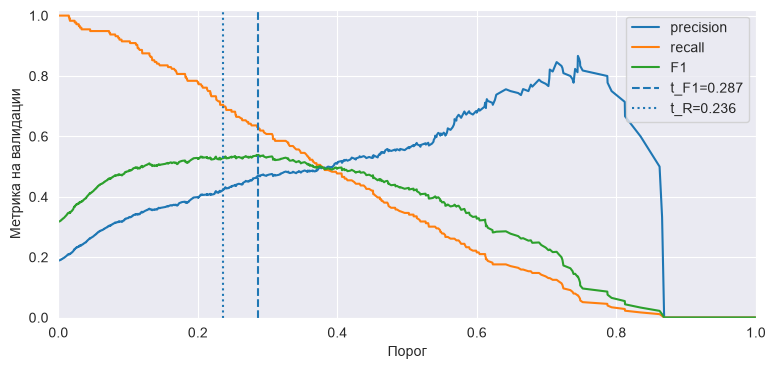

In [32]:
fig, ax = plt.subplots(figsize=(9, 4))
for name, values in [('precision', val_precision), ('recall', val_recall), ('F1', val_f1)]:
    ax.plot(thresholds, values, label=name)
ax.axvline(t_F1, linestyle='--', label=f't_F1={t_F1:.3f}')
ax.axvline(t_R, linestyle=':', label=f't_R={t_R:.3f}')
ax.set(xlabel='Порог', ylabel='Метрика на валидации', xlim=(0, 1), ylim=(0, 1.02))
ax.legend()
plt.show()
threshold_model = clone(baseline).fit(X_train, y_train)
threshold_proba = threshold_model.predict_proba(X_test)[:, 1]

def evaluate(model, X, y, threshold=0.5):
    score = model.predict_proba(X)[:, 1]
    prediction = (score >= threshold).astype(int)
    return {'threshold': float(threshold), 'accuracy': metrics.accuracy_score(y, prediction),
            'precision': metrics.precision_score(y, prediction, zero_division=0),
            'recall': metrics.recall_score(y, prediction, zero_division=0),
            'F1': metrics.f1_score(y, prediction, zero_division=0),
            'ROC-AUC': metrics.roc_auc_score(y, score),
            'PR-AUC': metrics.average_precision_score(y, score)}

threshold_results = pd.DataFrame({name: evaluate(threshold_model, X_test, y_test, t)
    for name, t in [('LR, t=0.5', 0.5), ('LR, t_F1', t_F1), ('LR, t_R', t_R)]}).T

In [33]:
threshold_results

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
"LR, t=0.5",0.500000,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
"LR, t_F1",0.286550,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766
"LR, t_R",0.236359,0.760025,0.421260,0.706271,0.527744,0.820876,0.484766


Порог для максимального F1 на валидации равен 0.28655. Порог для максимального precision при recall не ниже 0.7 равен 0.23636.

На тесте при пороге 0.23636 recall составляет 0.7063. Условие выполнилось. Однако валидационная оценка зависит от выборки, после переобучения модель меняется, а новые данные могут иметь другое распределение. Поэтому выполнение условия на новых данных не гарантируется.

Для сервиса я выбрал бы порог 0.23636. Он выбран по требованию recall не ниже 0.7 и на тесте дает precision 0.4213. При пороге для максимального F1 тестовый recall составляет только 0.6205.

## <font color="green">Часть 3. Несбалансированные классы (2.5 балла)</font>

Класс «хорошее вино» встречается примерно в 5 раз реже остальных. На семинаре 4 мы обсуждали, что с этим можно сделать:
- задать классам веса (`class_weight='balanced'`);
- сбалансировать обучающую выборку: undersampling, oversampling и их комбинации (библиотека [imbalanced-learn](https://imbalanced-learn.org/stable/)).

Во всех заданиях этой части сравнивайте модели по одному и тому же набору метрик на тестовой выборке: accuracy, precision, recall, $F_1$ (при пороге по умолчанию), ROC-AUC и PR-AUC. Удобно написать для этого одну функцию, которая принимает обученную модель и возвращает строку таблицы.

**Важно:** ресемплинг применяется **только к тренировочной выборке**. Тестовая выборка остаётся нетронутой, иначе метрики перестанут отражать качество на реальном распределении классов.

### Задание 3.1. Веса классов (0.5 балла)

Обучите логистическую регрессию в пайплайне со `StandardScaler` с параметром `class_weight=None` и `class_weight='balanced'`. Сведите метрики двух моделей в таблицу.

1. Какие веса получают объекты классов 0 и 1 при `class_weight='balanced'`? Посчитайте их по формуле из документации `sklearn`.
2. Какие метрики заметно изменились, а какие почти нет? Объясните, почему.

In [34]:
plain_model = clone(baseline).fit(X_train, y_train)
balanced_model = make_pipeline(StandardScaler(), LogisticRegression(
    class_weight='balanced', random_state=RANDOM_STATE)).fit(X_train, y_train)
class_counts = y_train.value_counts().sort_index()
class_weights = len(y_train) / (2 * class_counts)

In [35]:
pd.DataFrame({'n_train': class_counts, 'balanced_weight': class_weights})

,n_train,balanced_weight
target,,
0,3018,0.616965
1,706,2.637394


In [36]:
imbalance_models = {'LR, без весов': plain_model, 'LR, balanced': balanced_model}
imbalance_rows = {name: evaluate(model, X_test, y_test) for name, model in imbalance_models.items()}
imbalance_table = pd.DataFrame(imbalance_rows).T

In [37]:
imbalance_table

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
"LR, без весов",0.5,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
"LR, balanced",0.5,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147


Вес класса равен числу обучающих объектов, деленному на произведение числа классов и числа объектов этого класса. Вес класса 0 составляет 0.6170, класса 1 составляет 2.6374.

При использовании весов recall вырос с 0.3036 до 0.7855, F1 вырос с 0.3841 до 0.5289. Precision снизился с 0.5227 до 0.3987, accuracy снизилась с 0.8152 до 0.7343.

Редкий класс сильнее влияет на функцию потерь, поэтому модель чаще выбирает класс 1. ROC AUC почти не изменилась и осталась около 0.8209. PR AUC снизилась с 0.4848 до 0.4811. Порядок объектов по оценкам модели изменился мало.

### Задание 3.2. Ресемплинг (1 балл)

С помощью `imblearn.pipeline.make_pipeline` соберите пайплайны логистической регрессии с разными способами балансировки:
- `RandomUnderSampler`;
- `NearMiss(version=2)`;
- `RandomOverSampler`;
- `SMOTE`.

Для каждого метода выведите размеры классов в обучающей выборке после ресемплинга и добавьте строку в таблицу метрик из задания 3.1.

Ответьте на вопросы:
- Почему здесь нужен `make_pipeline` именно из `imblearn`, а не из `sklearn`? Что произойдёт с тестовой выборкой при вызове `predict` у такого пайплайна?
- Почему нельзя сначала сбалансировать весь датасет, а уже потом разбить его на train и test?
- Какой из методов оказался лучшим по PR-AUC, а какой – худшим? Как вы думаете, почему?
- Для каких из четырёх методов важен порядок шагов «ресемплинг» и «масштабирование» в пайплайне, а для каких нет? Почему? Проверьте на одном из методов, что изменится, если поменять шаги местами.

In [38]:
from imblearn.pipeline import make_pipeline as make_imblearn_pipeline
from imblearn.under_sampling import RandomUnderSampler, NearMiss
from imblearn.over_sampling import RandomOverSampler, SMOTE

samplers = {'RandomUnderSampler': RandomUnderSampler(random_state=RANDOM_STATE),
            'NearMiss v2': NearMiss(version=2),
            'RandomOverSampler': RandomOverSampler(random_state=RANDOM_STATE),
            'SMOTE': SMOTE(random_state=RANDOM_STATE)}
resampled_counts = {}
for name, sampler in samplers.items():
    pipeline = make_imblearn_pipeline(StandardScaler(), clone(sampler),
                                    LogisticRegression(random_state=RANDOM_STATE))
    pipeline.fit(X_train, y_train)
    imbalance_models[name] = pipeline
    imbalance_rows[name] = evaluate(pipeline, X_test, y_test)
    scaled_train = pipeline[0].transform(X_train)
    _, y_resampled = clone(sampler).fit_resample(scaled_train, y_train)
    resampled_counts[name] = pd.Series(y_resampled).value_counts().sort_index()
resampling_counts = pd.DataFrame(resampled_counts).T.rename(columns={0: 'class 0', 1: 'class 1'})

In [39]:
resampling_counts

target,class 0,class 1
RandomUnderSampler,706,706
NearMiss v2,706,706
RandomOverSampler,3018,3018
SMOTE,3018,3018


In [40]:
imbalance_table = pd.DataFrame(imbalance_rows).T

In [41]:
imbalance_table

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
"LR, без весов",0.5,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
"LR, balanced",0.5,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
RandomUnderSampler,0.5,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
NearMiss v2,0.5,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
RandomOverSampler,0.5,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
SMOTE,0.5,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606


In [42]:
reverse_nearmiss = make_imblearn_pipeline(NearMiss(version=2), StandardScaler(),
    LogisticRegression(random_state=RANDOM_STATE)).fit(X_train, y_train)
order_table = pd.DataFrame({
    'Scaler → NearMiss': imbalance_rows['NearMiss v2'],
    'NearMiss → Scaler': evaluate(reverse_nearmiss, X_test, y_test)}).T

In [43]:
order_table

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
Scaler → NearMiss,0.5,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
NearMiss → Scaler,0.5,0.630326,0.306343,0.749175,0.434866,0.742324,0.358085


In [44]:
print('Выборки NearMiss совпали:', np.array_equal(
    imbalance_models['NearMiss v2'][1].sample_indices_, reverse_nearmiss[0].sample_indices_))

Выборки NearMiss совпали: False


Нужен пайплайн imblearn, потому что методы балансировки меняют число объектов и соответствующие им метки. Обычный пайплайн sklearn не поддерживает такой шаг. При предсказании балансировка пропускается. Тестовая выборка только масштабируется и передается модели.

Если балансировать данные до разбиения, копии объектов или созданные по ним примеры могут попасть в разные выборки. Это создает утечку данных. Также тест перестает отражать исходное соотношение классов.

Среди четырех методов балансировки лучший PR AUC у RandomOverSampler, он равен 0.4811. Худший результат у NearMiss второй версии, он равен 0.4479. RandomOverSampler сохраняет все исходные объекты. NearMiss удаляет большую часть объектов класса 0 по расстояниям, что может исказить его распределение.

Для NearMiss и SMOTE важен масштаб признаков, потому что они используют расстояния между объектами. Перед ними нужно выполнять масштабирование. Случайные методы RandomUnderSampler и RandomOverSampler выбирают объекты независимо от масштаба.

При перестановке шагов результат модели может измениться у всех четырех методов, потому что масштабирование будет обучаться на другой выборке. Для NearMiss перестановка изменила выбранные объекты и снизила PR AUC с 0.4479 до 0.3581.

### Задание 3.3. Веса классов или порог? (0.75 балла)

Сравните на тестовой выборке две модели:
- логистическую регрессию с `class_weight='balanced'` и порогом 0.5;
- логистическую регрессию без весов с порогом $t_{F_1}$ из задания 2.5.

Постройте их PR-кривые на одном графике и отметьте на каждой кривой точку, соответствующую выбранному порогу. Сильно ли различаются кривые? Можно ли сказать, что взвешивание классов в основном «сдвигает порог»?

In [45]:
weight_vs_threshold = pd.DataFrame({
    'balanced, t=0.5': evaluate(balanced_model, X_test, y_test),
    'без весов, t_F1': evaluate(threshold_model, X_test, y_test, t_F1)}).T

In [46]:
weight_vs_threshold

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
"balanced, t=0.5",0.50000,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
"без весов, t_F1",0.28655,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766


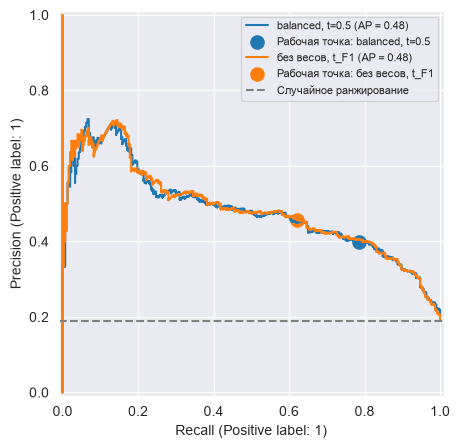

Свободные члены: [-2.08059721] [-0.65733905]
Корреляция коэффициентов: 0.9976300643169516


In [47]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, model, threshold in [('balanced, t=0.5', balanced_model, 0.5),
                                ('без весов, t_F1', threshold_model, t_F1)]:
    scores = model.predict_proba(X_test)[:, 1]
    metrics.PrecisionRecallDisplay.from_predictions(y_test, scores, name=name, ax=ax)
    row = evaluate(model, X_test, y_test, threshold)
    ax.scatter(row['recall'], row['precision'], s=90, marker='o', label=f'Рабочая точка: {name}')
ax.axhline(y_test.mean(), color='grey', linestyle='--', label='Случайное ранжирование')
ax.legend(fontsize=8)
plt.show()
coef_comparison = pd.DataFrame({'без весов': threshold_model[-1].coef_.ravel(),
                               'balanced': balanced_model[-1].coef_.ravel()}, index=X_train.columns)
print('Свободные члены:', threshold_model[-1].intercept_, balanced_model[-1].intercept_)
print('Корреляция коэффициентов:', coef_comparison.corr().iloc[0, 1])

In [48]:
coef_comparison

,без весов,balanced
fixed_acidity,0.849801,0.857564
volatile_acidity,-0.507229,-0.613834
citric_acid,0.035639,0.010652
residual_sugar,0.939425,0.966011
chlorides,-0.392188,-0.310551
free_sulfur_dioxide,0.319613,0.280975
total_sulfur_dioxide,-0.414304,-0.411039
density,-1.433730,-1.423347
pH,0.540641,0.538253
sulphates,0.377338,0.379537


Кривые близки. PR AUC модели с весами равна 0.4811, модели без весов 0.4848.

При весах balanced и пороге 0.5 precision составляет 0.3987, recall составляет 0.7855. Без весов при пороге для максимального F1 precision составляет 0.4574, recall составляет 0.6205.

В этом эксперименте взвешивание в основном похоже на сдвиг порога. Но оно меняет и коэффициенты модели, поэтому полного совпадения нет. Изменение только порога не меняет саму PR кривую.

### Задание 3.4. Итоги (0.25 балла)

Сведите в одну таблицу все модели частей 2 и 3 (метрики на тестовой выборке). Какую модель и какой порог вы бы предложили сервису из сценария? Обоснуйте выбор, опираясь на метрики.

In [49]:
all_rows = {'Всегда 0': {'threshold': np.nan, 'accuracy': constant_accuracy,
    'precision': 0.0, 'recall': 0.0, 'F1': 0.0, 'ROC-AUC': 0.5, 'PR-AUC': y_test.mean()},
    'Свой GD, t=0.5': evaluate(wine_gd, X_test, y_test), **imbalance_rows,
    'LR, t_F1': evaluate(threshold_model, X_test, y_test, t_F1),
    'LR, t_R': evaluate(threshold_model, X_test, y_test, t_R),
    'NearMiss → Scaler': evaluate(reverse_nearmiss, X_test, y_test)}
all_results = pd.DataFrame(all_rows).T

In [50]:
all_results

,threshold,accuracy,precision,recall,F1,ROC-AUC,PR-AUC
Всегда 0,NaN,0.810150,0.000000,0.000000,0.000000,0.500000,0.189850
"Свой GD, t=0.5",0.500000,0.814536,0.520000,0.300330,0.380753,0.820562,0.483769
"LR, без весов",0.500000,0.815163,0.522727,0.303630,0.384134,0.820876,0.484766
"LR, balanced",0.500000,0.734336,0.398660,0.785479,0.528889,0.820935,0.481147
RandomUnderSampler,0.500000,0.733083,0.395939,0.772277,0.523490,0.820628,0.479891
NearMiss v2,0.500000,0.646617,0.329412,0.831683,0.471910,0.786523,0.447903
RandomOverSampler,0.500000,0.733083,0.398010,0.792079,0.529801,0.821108,0.481077
SMOTE,0.500000,0.734962,0.397611,0.768977,0.524184,0.819595,0.479606
"LR, t_F1",0.286550,0.788221,0.457421,0.620462,0.526611,0.820876,0.484766
"LR, t_R",0.236359,0.760025,0.421260,0.706271,0.527744,0.820876,0.484766


In [51]:
final_model = threshold_model
final_threshold = t_R

Я предложил бы логистическую регрессию без весов классов с масштабированием признаков и порогом 0.23636.

При этом пороге на тесте precision равна 0.4213, recall равен 0.7063, F1 равен 0.5277. Условие recall не ниже 0.7 выполнено. Модель с весами balanced дает больший recall, но ее precision ниже и составляет 0.3987.

Выбранный порог дает более высокую точность рекомендаций при выполнении требования к recall. Он подобран на валидации.

### Сохранение модели (0 баллов, нужно для части 4)

Сохраните итоговую модель (весь пайплайн, а не только `LogisticRegression`), выбранный порог и тестовую выборку – они понадобятся в приложении. Допишите ячейку под свою итоговую модель.

Если работаете в Colab, скачайте папку `wine_app/` на свой компьютер (например, заархивируйте её и воспользуйтесь `google.colab.files.download`): приложение запускается локально.

In [52]:
import json
import joblib
import importlib.metadata as metadata

app_dir = BASE_DIR / 'wine_app'
app_dir.mkdir(exist_ok=True)
joblib.dump(final_model, app_dir / 'model.joblib')
config = {'threshold': float(final_threshold), 'random_state': RANDOM_STATE,
          'selection': 'max validation precision subject to recall >= 0.7',
          'features': X_train.columns.tolist()}
(app_dir / 'config.json').write_text(json.dumps(config, ensure_ascii=False, indent=2) + '\n')
X_test.assign(target=y_test).to_csv(app_dir / 'test.csv', index=False)
X_test.head(5).to_csv(app_dir / 'example_wines.csv', index=False)
all_results.to_csv(app_dir / 'model_comparison.csv', index_label='model')
validation_choices.to_csv(app_dir / 'validation_thresholds.csv', index_label='rule')
packages = ['streamlit', 'scikit-learn', 'numpy', 'pandas', 'scipy', 'matplotlib', 'joblib']
(app_dir / 'requirements.txt').write_text(''.join(f'{p}=={metadata.version(p)}\n' for p in packages))
print('Сохранён весь пайплайн:', app_dir / 'model.joblib')
print('Порог:', final_threshold)
report = {'convergence': convergence.reset_index().to_dict('records'),
          'eta': eta_table.reset_index().to_dict('records'),
          'synthetic': synthetic_metrics.reset_index().to_dict('records'),
          'weight_difference': float(np.max(np.abs(gd.w - weights.sklearn.to_numpy()))),
          'unregularized_difference': float(np.max(np.abs(gd_converged.w - w_sk))),
          'prevalence': prevalence.to_dict(), 'duplicates': duplicate_count,
          'shape': list(df.shape), 'train_shape': list(X_train.shape), 'test_shape': list(X_test.shape),
          'cm': {'TP': TP, 'TN': TN, 'FP': FP, 'FN': FN},
          'auc': auc_table.reset_index().to_dict('records'),
          'transforms': auc_transforms.to_dict(), 'validation': validation_choices.reset_index().to_dict('records'),
          'all_results': all_results.reset_index(names='model').to_dict('records'),
          'class_weights': class_weights.to_dict(), 'order': order_table.reset_index(names='order').to_dict('records')}
report_text = json.dumps(report, ensure_ascii=False, indent=2)
(BASE_DIR / 'results.json').write_text(report_text.replace('NaN', 'null') + '\n')

Сохранён весь пайплайн: /Users/nenikitata/HSE/ml_hse_2026/homework/hw_3/wine_app/model.joblib
Порог: 0.23635860938278724


6382

## <font color="green">Часть 4. Демо-приложение на Streamlit (2.5 балла)</font>

Модель в ноутбуке видите только вы. Чтобы ей мог пользоваться сомелье сервиса (и чтобы он понимал, почему меняется подборка при изменении порога), сделаем небольшое веб-приложение.

[Streamlit](https://docs.streamlit.io/) это библиотека, которая которая превращает обычный Python-скрипт в веб-страницу: каждый вызов вроде `st.slider(...)` или `st.write(...)` рисует элемент интерфейса, а при любом действии пользователя скрипт перезапускается сверху вниз. Минимальный пример:

```python
import streamlit as st

t = st.slider('Порог', 0.0, 1.0, 0.5)
st.write('Вы выбрали порог', t)
```

Приложение запускается **локально**, а не в Colab:

```bash
pip install streamlit
streamlit run app.py
```

Полезные элементы: [`st.number_input`](https://docs.streamlit.io/develop/api-reference/widgets/st.number_input), [`st.slider`](https://docs.streamlit.io/develop/api-reference/widgets/st.slider), [`st.tabs`](https://docs.streamlit.io/develop/api-reference/layout/st.tabs), [`st.file_uploader`](https://docs.streamlit.io/develop/api-reference/widgets/st.file_uploader), [`st.download_button`](https://docs.streamlit.io/develop/api-reference/widgets/st.download_button), [`st.pyplot`](https://docs.streamlit.io/develop/api-reference/charts/st.pyplot), [`st.metric`](https://docs.streamlit.io/develop/api-reference/data/st.metric), [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource) (чтобы не загружать модель заново при каждом перезапуске скрипта).

Приложение `wine_app/app.py` использует файлы, сохранённые в ячейке выше (`model.joblib`, `config.json`, `test.csv`). **Модель внутри приложения не обучается.**

### Задание 4.1. Оценка одного вина (0.5 балла)

Сделайте вкладку, на которой пользователь вводит 12 признаков вина (диапазоны и значения по умолчанию возьмите из данных, например минимум, максимум и медиану по `test.csv`; признак `is_red` – переключатель «красное / белое»). Сделайте сайдбар с интерактивным ползунком значения порога, установите порог по умолчанию значением из файла `config.json`. Приложение показывает вероятность того, что вино хорошее, и решение модели при установленном пороге.

### Задание 4.2. Интерактивная визуализация модельных метрик (0.5 балла)

Сделайте вкладку «Модельные метрики». При изменении порога на тестовой выборке пересчитываются и выводятся:
- матрица ошибок;
- precision, recall и $F_1$;
- ROC- и PR-кривые, на которых отмечена точка, соответствующая текущему порогу.

Добавьте короткий текст для сомелье: что произойдёт с подборкой, если порог увеличить или уменьшить.

### Задание 4.3. Пакетное предсказание (0.5 балла)

Сделайте вкладку, на которой пользователь загружает CSV-файл с признаками вин (без столбца `target`), а приложение показывает таблицу с вероятностью и решением для каждого вина и даёт скачать её через `st.download_button`. Порог для этой вкладки берётся из слайдера задания 4.2 (подсказка: [`st.session_state`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.session_state)) или задаётся отдельно – на ваш выбор.

Приложение не должно падать, если в файле не хватает столбцов: в этом случае выведите понятное сообщение об ошибке (`st.error`).

### Задание 4.4. Что выучила модель (0.25 балла)

Сделайте вкладку с горизонтальной столбчатой диаграммой коэффициентов логистической регрессии (после масштабирования признаков), отсортированных по значению. Подпишите, какие признаки сильнее всего «голосуют» за хорошее вино, а какие – против.

### Задание 4.5. Кэширование (0.25 балла)

Streamlit выполняет `app.py` заново при каждом действии пользователя: сдвинули слайдер порога – скрипт отработал сверху вниз ещё раз. Без кэширования при каждом движении слайдера модель снова читается с диска, а вероятности на тестовой выборке пересчитываются, хотя от порога они не зависят.

1. Модель загружается функцией с декоратором [`st.cache_resource`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_resource): один объект на весь сервер. Путь к файлу строится от папки, где лежит `app.py` (`Path(__file__).parent`), а не от текущей директории.
2. `test.csv` читается функцией с декоратором [`st.cache_data`](https://docs.streamlit.io/develop/api-reference/caching-and-state/st.cache_data).
3. Вероятности класса 1 на тестовой выборке считаются один раз, в функции с `st.cache_data`. При движении слайдера в задании 4.2 меняется только сравнение с порогом, `predict_proba` заново не вызывается. Подсказка: аргумент, который Streamlit не должен хешировать (например, модель), называют с подчёркиванием в начале: `def test_proba(_model, X): ...`.

Ответьте в `README.md` или в комментарии в `app.py`: почему для модели используется `st.cache_resource`, а для таблиц – `st.cache_data`? Что изменится, если вызвать `joblib.load` без декоратора?

Использование `joblib.load` без декоратора или загрузка модели через `st.cache_data` за этот пункт не засчитываются.

### Задание 4.6. Оформление и сдача (0.5 балла)

1. Сдайте папку `wine_app/` (архивом или укажите в клетке ниже ссылку на Github репозиторий) со следующим содержимым:
- `app.py`;
- `model.joblib`, `config.json`, `test.csv`;
- `requirements.txt` с версиями библиотек, при которых приложение запускается;
- `README.md`: инструкция о том, как запустить приложение с указанием версии Python интерпретатора.

2. Проведите деплой приложения на [Streamlit Community Cloud](https://streamlit.io/cloud).

**Опишите общие мысли о работе. Это место для вашей рефлексии – необязательное, но полезное.** 🍷

Приложение находится в папке wine_app. Архив для сдачи называется wine_app.zip. Инструкция запуска находится в файле README.md внутри папки приложения.

Публикация в Streamlit Community Cloud пока не выполнена. Ссылки на приложение нет.